In [3]:
import torch, os
print(torch.__version__, "| CUDA:", torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert torch.cuda.is_available(), "Turn on the GPU accelerator and restart the session!"

for root, dirs, files in os.walk('/kaggle/input'):
    print(root, "| subfolders:", len(dirs), "| files:", len(files))

2.11.0+cu128 | CUDA: True
/kaggle/input | subfolders: 1 | files: 0
/kaggle/input/datasets | subfolders: 1 | files: 0
/kaggle/input/datasets/almightyj | subfolders: 1 | files: 0
/kaggle/input/datasets/almightyj/person-face-sketches | subfolders: 3 | files: 0
/kaggle/input/datasets/almightyj/person-face-sketches/val | subfolders: 2 | files: 0
/kaggle/input/datasets/almightyj/person-face-sketches/val/photos | subfolders: 0 | files: 1000
/kaggle/input/datasets/almightyj/person-face-sketches/val/sketches | subfolders: 0 | files: 1000
/kaggle/input/datasets/almightyj/person-face-sketches/test | subfolders: 2 | files: 0
/kaggle/input/datasets/almightyj/person-face-sketches/test/photos | subfolders: 0 | files: 679
/kaggle/input/datasets/almightyj/person-face-sketches/test/sketches | subfolders: 0 | files: 679
/kaggle/input/datasets/almightyj/person-face-sketches/train | subfolders: 2 | files: 0
/kaggle/input/datasets/almightyj/person-face-sketches/train/photos | subfolders: 0 | files: 20655
/k

# Cell 2: Imports and settings

In [4]:
import glob, random, time, itertools, numpy as np, matplotlib.pyplot as plt
from PIL import Image
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

random.seed(0); np.random.seed(0); torch.manual_seed(0)

# ---------------- hyperparameters ----------------
IMG        = 128      # image size (128 = fast; use 256 for better quality if time allows)
BATCH      = 4
N_RES      = 6        # residual blocks (paper: 6 for 128px, 9 for 256px)
LR         = 2e-4
EPOCHS      = 30
DECAY_START = 15     # lr is constant until this epoch, then decays linearly to 0
LAMBDA_CYC = 10.0     # cycle-consistency weight (paper)
LAMBDA_ID  = 5.0      # identity weight (0.5 * lambda_cyc, as in the paper's code)
MAX_HOURS  = 8.5      # stop safely before the Kaggle session limit (resume later)
OUT = '/kaggle/working'
os.makedirs(f'{OUT}/samples', exist_ok=True)

# Cell 3: Find photos (domain A) and sketches (domain B)

In [5]:
EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
all_files = sorted(os.path.join(r, f) for r, _, fs in os.walk('/kaggle/input')
                   for f in fs if f.lower().endswith(EXTS))
print("Total images found:", len(all_files))

IGNORE = {'kaggle', 'input', 'datasets', 'almightyj', 'person-face-sketches'}
def label(p):
    """'B' if a folder name (ignoring the dataset's own name) says sketch, else 'A'."""
    parts = [x.lower() for x in os.path.dirname(p).split(os.sep) if x.lower() not in IGNORE]
    return 'B' if any('sketch' in x for x in parts) else 'A'

files_A = [p for p in all_files if label(p) == 'A']
files_B = [p for p in all_files if label(p) == 'B']
print("Domain A (photos):", len(files_A), "| Domain B (sketches):", len(files_B))
print("Example A:", files_A[:2]); print("Example B:", files_B[:2])

# Some versions store photo+sketch side by side in ONE image (pix2pix style). Check:
w, h = Image.open(all_files[0]).size
print("First image size:", (w, h))
SIDE_BY_SIDE = (w == 2 * h)     # True => each file holds [photo | sketch]
SWAP = False                    # set True if the left half turns out to be the sketch
print("Side-by-side format:", SIDE_BY_SIDE)

Total images found: 44668
Domain A (photos): 22334 | Domain B (sketches): 22334
Example A: ['/kaggle/input/datasets/almightyj/person-face-sketches/test/photos/10132.jpg', '/kaggle/input/datasets/almightyj/person-face-sketches/test/photos/1020.jpg']
Example B: ['/kaggle/input/datasets/almightyj/person-face-sketches/test/sketches/10132.jpg', '/kaggle/input/datasets/almightyj/person-face-sketches/test/sketches/1020.jpg']
First image size: (512, 512)
Side-by-side format: False


# Cell 4: Load into memory, split, preview

Loaded in 57s | train A/B: 2000/2000 | test A/B: 200/200


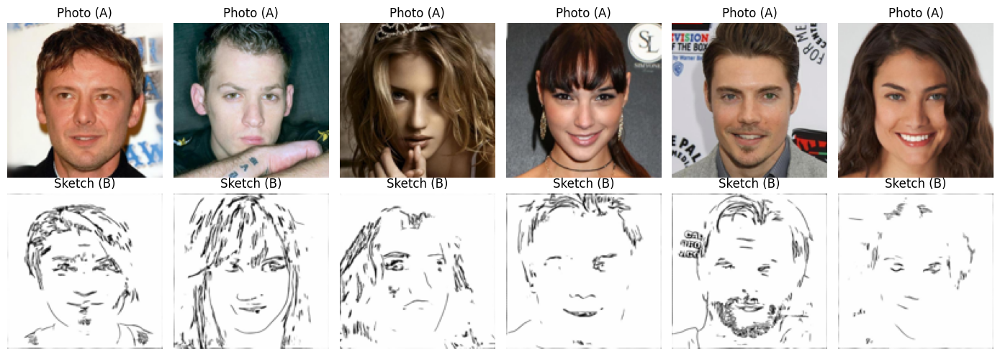

In [6]:
BASE = '/kaggle/input/datasets/almightyj/person-face-sketches'
TRAIN_N = 2000    # training images per domain (raise it if epochs are fast enough)
TEST_N  = 200     # held-out test images per domain

def list_imgs(split, kind):
    return sorted(glob.glob(f'{BASE}/{split}/{kind}/*.*'))

def load_subset(paths, n, seed):
    """Random subset of n images, resized to IMG x IMG, returned as uint8 arrays."""
    paths = random.Random(seed).sample(paths, min(n, len(paths)))
    return [np.asarray(Image.open(p).convert('RGB').resize((IMG, IMG), Image.BICUBIC)) for p in paths]

t0 = time.time()
trainA = load_subset(list_imgs('train', 'photos'),   TRAIN_N, 1)
trainB = load_subset(list_imgs('train', 'sketches'), TRAIN_N, 2)   # different seed: truly unpaired
testA  = load_subset(list_imgs('test',  'photos'),   TEST_N,  3)
testB  = load_subset(list_imgs('test',  'sketches'), TEST_N,  4)
arrA, arrB = trainA, trainB            # used later by Cell 13 (sketch detector calibration)
print(f"Loaded in {time.time()-t0:.0f}s | train A/B: {len(trainA)}/{len(trainB)} | test A/B: {len(testA)}/{len(testB)}")

# Preview: top row must be photos, bottom row sketches
fig, ax = plt.subplots(2, 6, figsize=(14, 5))
for i in range(6):
    ax[0, i].imshow(trainA[i]); ax[0, i].set_title('Photo (A)')
    ax[1, i].imshow(trainB[i]); ax[1, i].set_title('Sketch (B)')
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

# Cell 5: Unpaired dataset and loader

In [7]:
def to_tensor(a):                      # uint8 HWC -> float CHW in [-1, 1]
    return torch.from_numpy(np.ascontiguousarray(a).copy()).permute(2, 0, 1).float() / 127.5 - 1.0

class UnpairedDS(Dataset):
    """CycleGAN is unpaired: A is taken in order, B is drawn at random each time."""
    def __init__(self, A, B, augment=True):
        self.A, self.B, self.aug = A, B, augment
    def __len__(self): return max(len(self.A), len(self.B))
    def __getitem__(self, i):
        a = self.A[i % len(self.A)]
        b = self.B[random.randrange(len(self.B))]
        if self.aug and random.random() < 0.5: a = a[:, ::-1].copy()   # random horizontal flip
        if self.aug and random.random() < 0.5: b = b[:, ::-1].copy()
        return to_tensor(a), to_tensor(b)

train_dl = DataLoader(UnpairedDS(trainA, trainB), batch_size=BATCH, shuffle=True,
                      num_workers=0, drop_last=True)
a, b = next(iter(train_dl)); print(a.shape, b.shape, a.min().item(), a.max().item())
print("Steps per epoch:", len(train_dl))

torch.Size([4, 3, 128, 128]) torch.Size([4, 3, 128, 128]) -1.0 0.9372549057006836
Steps per epoch: 500


# Cell 6: Model architecture (from the paper)

In [8]:
class ResBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.b = nn.Sequential(
            nn.ReflectionPad2d(1), nn.Conv2d(c, c, 3), nn.InstanceNorm2d(c), nn.ReLU(True),
            nn.ReflectionPad2d(1), nn.Conv2d(c, c, 3), nn.InstanceNorm2d(c))
    def forward(self, x): return x + self.b(x)

class Generator(nn.Module):
    """c7s1-64, d128, d256, R256 x N, u128, u64, c7s1-3 (ResNet generator of the paper)."""
    def __init__(self, n_res=6, nf=64):
        super().__init__()
        L = [nn.ReflectionPad2d(3), nn.Conv2d(3, nf, 7), nn.InstanceNorm2d(nf), nn.ReLU(True)]
        c = nf
        for _ in range(2):                                   # 2 downsampling blocks
            L += [nn.Conv2d(c, c * 2, 3, 2, 1), nn.InstanceNorm2d(c * 2), nn.ReLU(True)]; c *= 2
        L += [ResBlock(c) for _ in range(n_res)]             # residual blocks
        for _ in range(2):                                   # 2 upsampling blocks
            L += [nn.ConvTranspose2d(c, c // 2, 3, 2, 1, output_padding=1),
                  nn.InstanceNorm2d(c // 2), nn.ReLU(True)]; c //= 2
        L += [nn.ReflectionPad2d(3), nn.Conv2d(c, 3, 7), nn.Tanh()]
        self.net = nn.Sequential(*L)
    def forward(self, x): return self.net(x)

class Discriminator(nn.Module):
    """70x70 PatchGAN: C64-C128-C256-C512 then a 1-channel output map."""
    def __init__(self, nf=64):
        super().__init__()
        def blk(i, o, s, norm=True):
            return [nn.Conv2d(i, o, 4, s, 1)] + ([nn.InstanceNorm2d(o)] if norm else []) + [nn.LeakyReLU(0.2, True)]
        self.net = nn.Sequential(*blk(3, nf, 2, False), *blk(nf, nf*2, 2), *blk(nf*2, nf*4, 2),
                                 *blk(nf*4, nf*8, 1), nn.Conv2d(nf*8, 1, 4, 1, 1))
    def forward(self, x): return self.net(x)

def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)): nn.init.normal_(m.weight, 0.0, 0.02)

G_AB = Generator(N_RES).to(device)   # photo  -> sketch
G_BA = Generator(N_RES).to(device)   # sketch -> photo
D_A  = Discriminator().to(device)    # judges real vs fake photos
D_B  = Discriminator().to(device)    # judges real vs fake sketches
for m in (G_AB, G_BA, D_A, D_B): m.apply(init_weights)

with torch.no_grad():
    print("G out:", G_AB(torch.zeros(1, 3, IMG, IMG, device=device)).shape,
          "| D out:", D_A(torch.zeros(1, 3, IMG, IMG, device=device)).shape)
print("Params G:", sum(p.numel() for p in G_AB.parameters()), "| D:", sum(p.numel() for p in D_A.parameters()))

G out: torch.Size([1, 3, 128, 128]) | D out: torch.Size([1, 1, 14, 14])
Params G: 7837699 | D: 2764737


# Cell 7: Losses, optimizers, schedulers, image buffer

In [9]:
class ImageBuffer:
    """Keeps the last 50 generated images; the discriminator sees a mix of new and old fakes."""
    def __init__(self, size=50): self.size, self.data = size, []
    def push_pop(self, imgs):
        out = []
        for im in imgs.detach():
            im = im.unsqueeze(0)
            if len(self.data) < self.size:
                self.data.append(im); out.append(im)
            elif random.random() > 0.5:
                i = random.randrange(self.size); out.append(self.data[i].clone()); self.data[i] = im
            else:
                out.append(im)
        return torch.cat(out)

buf_A, buf_B = ImageBuffer(), ImageBuffer()
mse, l1 = nn.MSELoss(), nn.L1Loss()          # LSGAN adversarial loss + L1 for cycle/identity

optG = torch.optim.Adam(itertools.chain(G_AB.parameters(), G_BA.parameters()), lr=LR, betas=(0.5, 0.999))
optD = torch.optim.Adam(itertools.chain(D_A.parameters(), D_B.parameters()), lr=LR, betas=(0.5, 0.999))

def lr_lambda(ep):   # constant, then linear decay to 0
    return 1.0 - max(0, ep - DECAY_START) / float(EPOCHS - DECAY_START + 1)
schG = torch.optim.lr_scheduler.LambdaLR(optG, lr_lambda)
schD = torch.optim.lr_scheduler.LambdaLR(optD, lr_lambda)

# Cell 8: Checkpoint save and resume (required by the brief)

In [10]:
CKPT = f'{OUT}/last.pth'
history = {'G': [], 'D': [], 'cyc': [], 'idt': []}

def save_ckpt(epoch):
    """Save everything needed to resume. Written to a temp file first so a crash can't corrupt it."""
    state = {'epoch': epoch, 'G_AB': G_AB.state_dict(), 'G_BA': G_BA.state_dict(),
             'D_A': D_A.state_dict(), 'D_B': D_B.state_dict(),
             'optG': optG.state_dict(), 'optD': optD.state_dict(),
             'schG': schG.state_dict(), 'schD': schD.state_dict(), 'history': history}
    torch.save(state, CKPT + '.tmp'); os.replace(CKPT + '.tmp', CKPT)          # always the latest
    if epoch % 10 == 0:                                                        # small milestones
        torch.save({'G_AB': G_AB.state_dict(), 'G_BA': G_BA.state_dict()}, f'{OUT}/gen_ep{epoch}.pth')

def load_ckpt(path):
    """Restore a checkpoint; returns the epoch to continue from."""
    global history
    c = torch.load(path, map_location=device, weights_only=False)
    G_AB.load_state_dict(c['G_AB']); G_BA.load_state_dict(c['G_BA'])
    D_A.load_state_dict(c['D_A']);   D_B.load_state_dict(c['D_B'])
    optG.load_state_dict(c['optG']); optD.load_state_dict(c['optD'])
    schG.load_state_dict(c['schG']); schD.load_state_dict(c['schD'])
    history = c['history']
    print(f"Resumed from epoch {c['epoch']}"); return c['epoch']

# Resume: use the file in this session, or one from a previous notebook version's output
RESUME_FROM = None   # e.g. '/kaggle/input/<your-notebook-name>/last.pth'
start_epoch = 0
if RESUME_FROM and os.path.exists(RESUME_FROM): start_epoch = load_ckpt(RESUME_FROM)
elif os.path.exists(CKPT):                      start_epoch = load_ckpt(CKPT)
print("Starting at epoch", start_epoch)

Starting at epoch 0


# Cell 9: Sample-grid helper

In [11]:
@torch.no_grad()
def make_grid(real_A, real_B, path=None, show=False):
    """Rows: real A | fake B | rec A   and   real B | fake A | rec B."""
    G_AB.eval(); G_BA.eval()
    fB, fA = G_AB(real_A), G_BA(real_B)
    rows = [real_A, fB, G_BA(fB), real_B, fA, G_AB(fA)]
    n = real_A.size(0)
    fig, ax = plt.subplots(6, n, figsize=(2 * n, 12))
    titles = ['Real photo', 'Fake sketch', 'Reconstructed photo', 'Real sketch', 'Fake photo', 'Reconstructed sketch']
    for r, t in enumerate(rows):
        for j in range(n):
            ax[r, j].imshow(((t[j].permute(1, 2, 0).cpu().numpy() + 1) / 2).clip(0, 1)); ax[r, j].axis('off')
        ax[r, 0].set_title(titles[r], fontsize=9, loc='left')
    plt.tight_layout()
    if path: plt.savefig(path, dpi=80)
    if show: plt.show()
    plt.close(fig); G_AB.train(); G_BA.train()

fixed_A = torch.stack([to_tensor(a) for a in testA[:6]]).to(device)
fixed_B = torch.stack([to_tensor(b) for b in testB[:6]]).to(device)

# Cell 10: Training loop

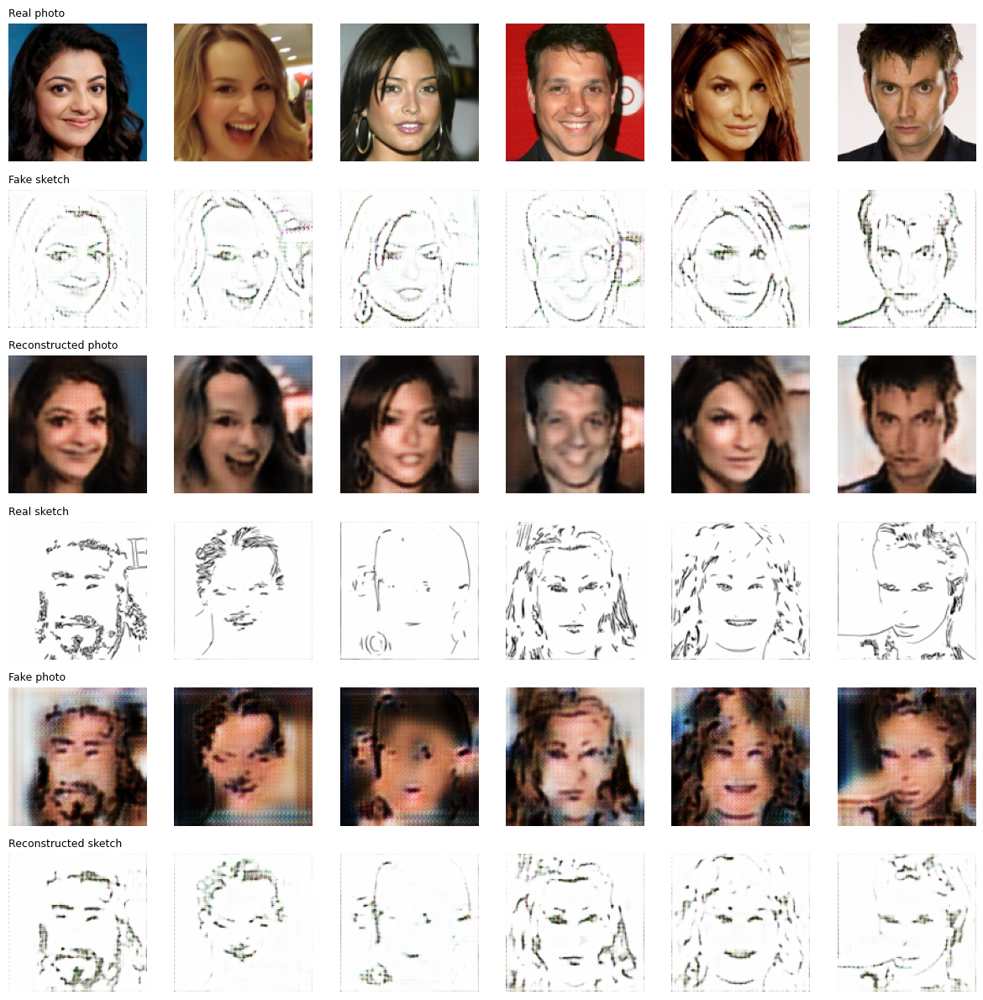

Epoch 1/30 | G_gan 0.961 D 0.638 cyc 3.401 idt 1.491 | lr 2.00e-04 | 226s
Epoch 2/30 | G_gan 0.861 D 0.429 cyc 2.559 idt 1.076 | lr 2.00e-04 | 228s
Epoch 3/30 | G_gan 0.975 D 0.357 cyc 2.364 idt 0.969 | lr 2.00e-04 | 229s
Epoch 4/30 | G_gan 0.927 D 0.368 cyc 2.234 idt 0.900 | lr 2.00e-04 | 228s


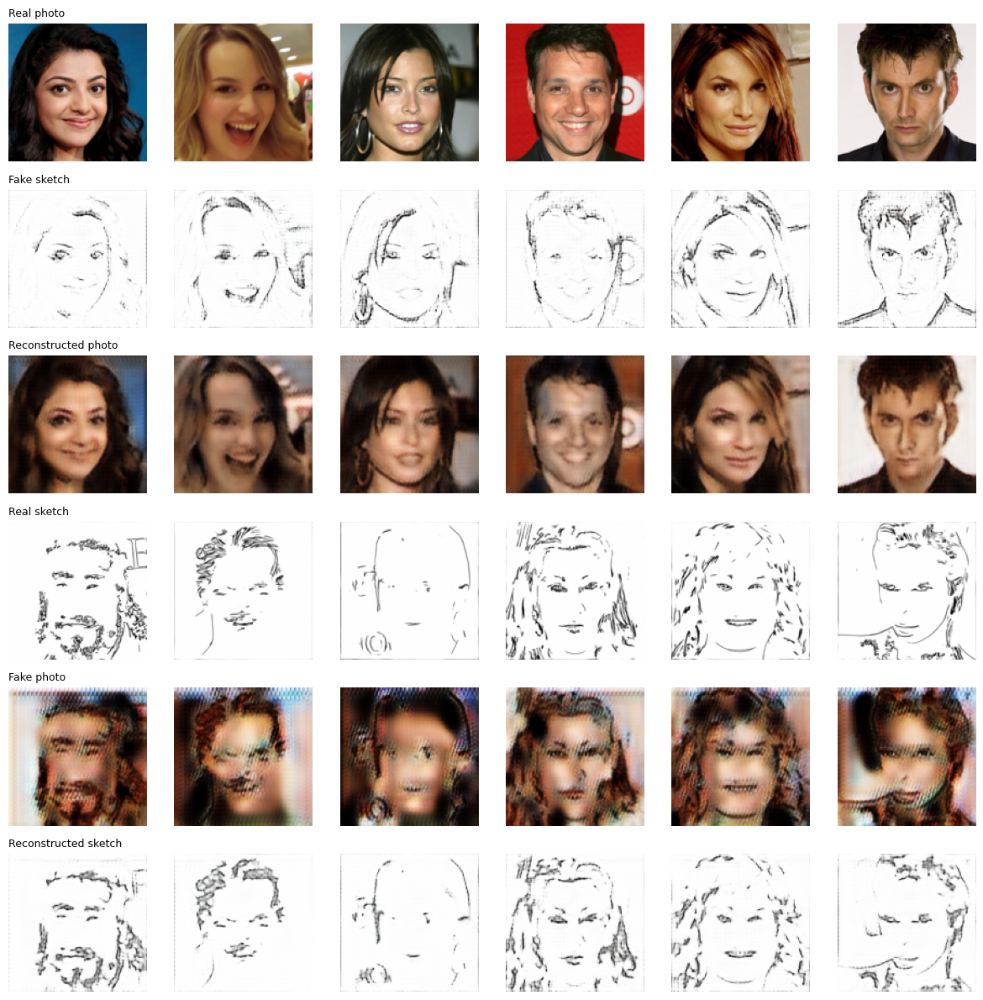

Epoch 5/30 | G_gan 0.966 D 0.336 cyc 2.095 idt 0.841 | lr 2.00e-04 | 229s
Epoch 6/30 | G_gan 1.034 D 0.300 cyc 2.097 idt 0.826 | lr 2.00e-04 | 228s
Epoch 7/30 | G_gan 1.068 D 0.280 cyc 2.083 idt 0.811 | lr 2.00e-04 | 229s
Epoch 8/30 | G_gan 1.057 D 0.284 cyc 1.990 idt 0.759 | lr 2.00e-04 | 228s
Epoch 9/30 | G_gan 1.046 D 0.281 cyc 1.946 idt 0.733 | lr 2.00e-04 | 228s


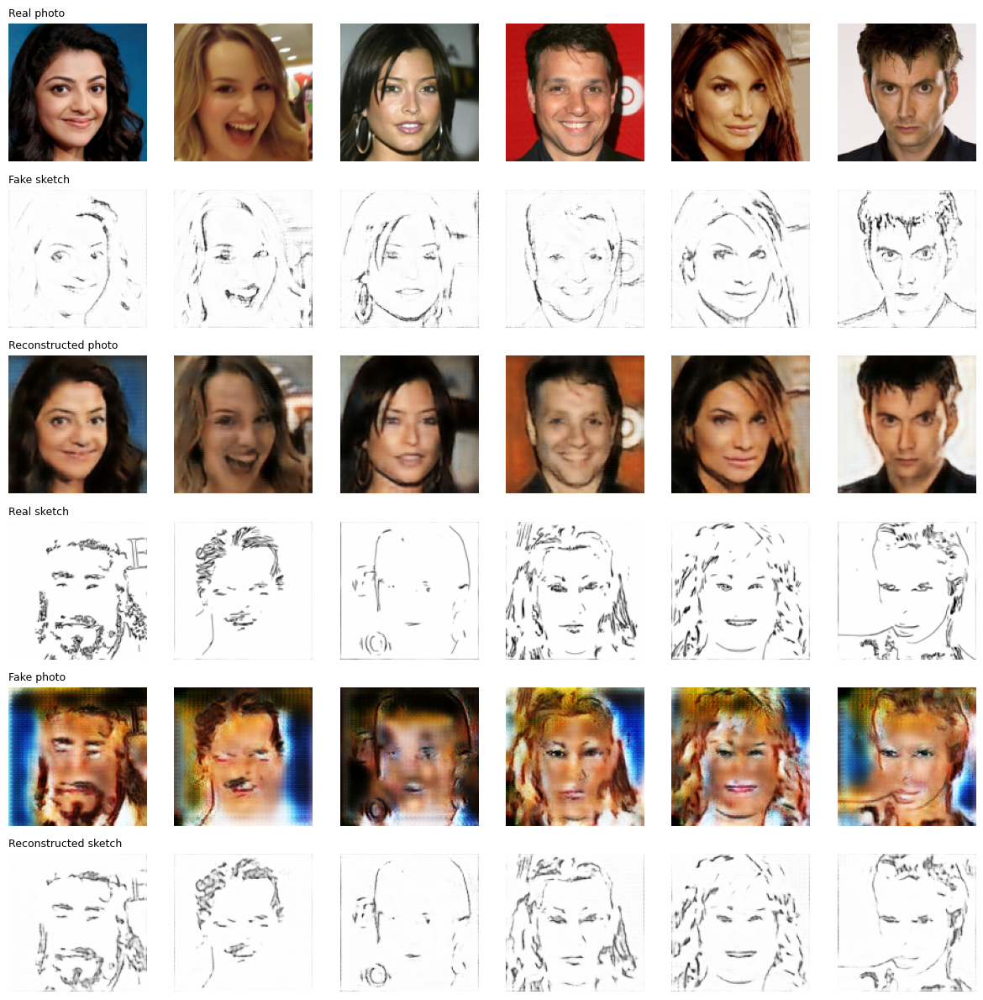

Epoch 10/30 | G_gan 1.049 D 0.275 cyc 1.901 idt 0.715 | lr 2.00e-04 | 229s
Epoch 11/30 | G_gan 1.059 D 0.269 cyc 1.896 idt 0.703 | lr 2.00e-04 | 229s
Epoch 12/30 | G_gan 0.936 D 0.439 cyc 1.745 idt 0.668 | lr 2.00e-04 | 228s
Epoch 13/30 | G_gan 0.601 D 0.513 cyc 1.553 idt 0.634 | lr 2.00e-04 | 228s
Epoch 14/30 | G_gan 0.797 D 0.384 cyc 1.596 idt 0.630 | lr 2.00e-04 | 228s


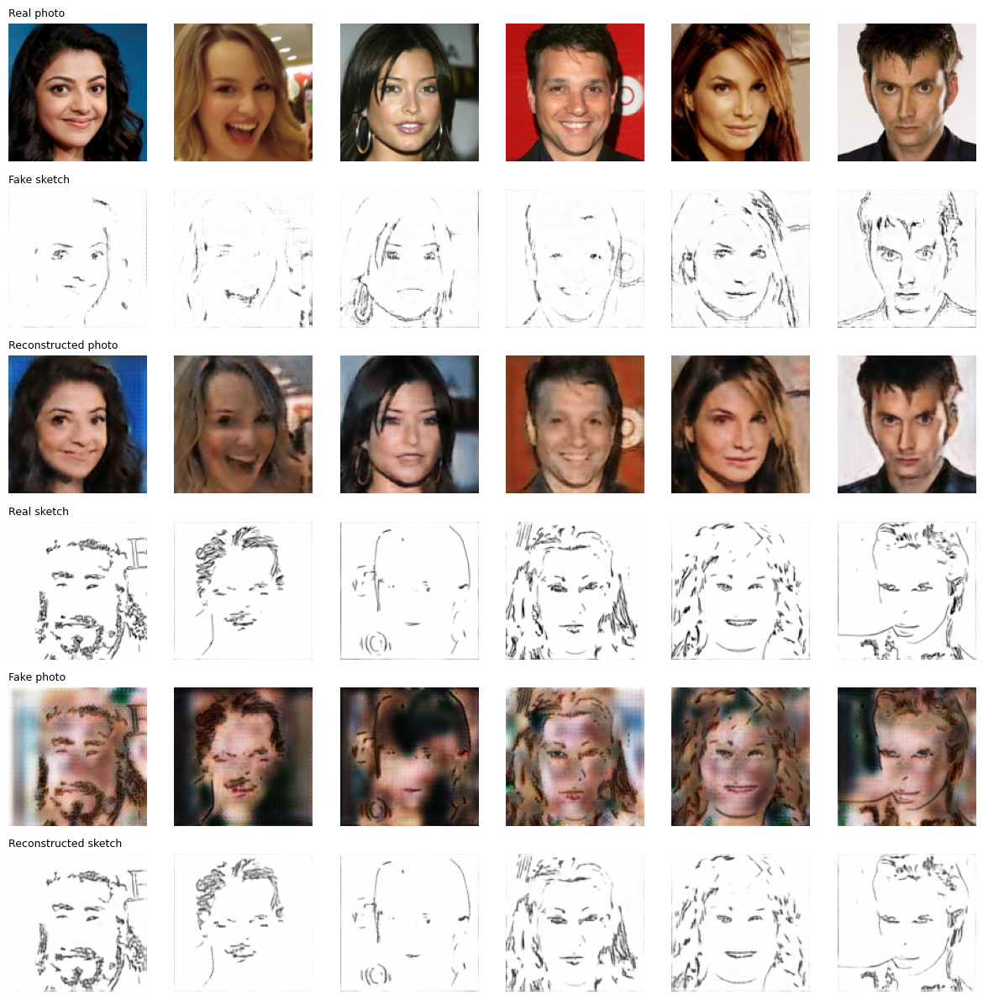

Epoch 15/30 | G_gan 0.854 D 0.371 cyc 1.604 idt 0.627 | lr 2.00e-04 | 230s
Epoch 16/30 | G_gan 0.860 D 0.363 cyc 1.608 idt 0.615 | lr 1.88e-04 | 228s
Epoch 17/30 | G_gan 0.947 D 0.310 cyc 1.633 idt 0.609 | lr 1.75e-04 | 228s
Epoch 18/30 | G_gan 1.044 D 0.258 cyc 1.651 idt 0.602 | lr 1.63e-04 | 229s
Epoch 19/30 | G_gan 1.032 D 0.254 cyc 1.635 idt 0.588 | lr 1.50e-04 | 228s


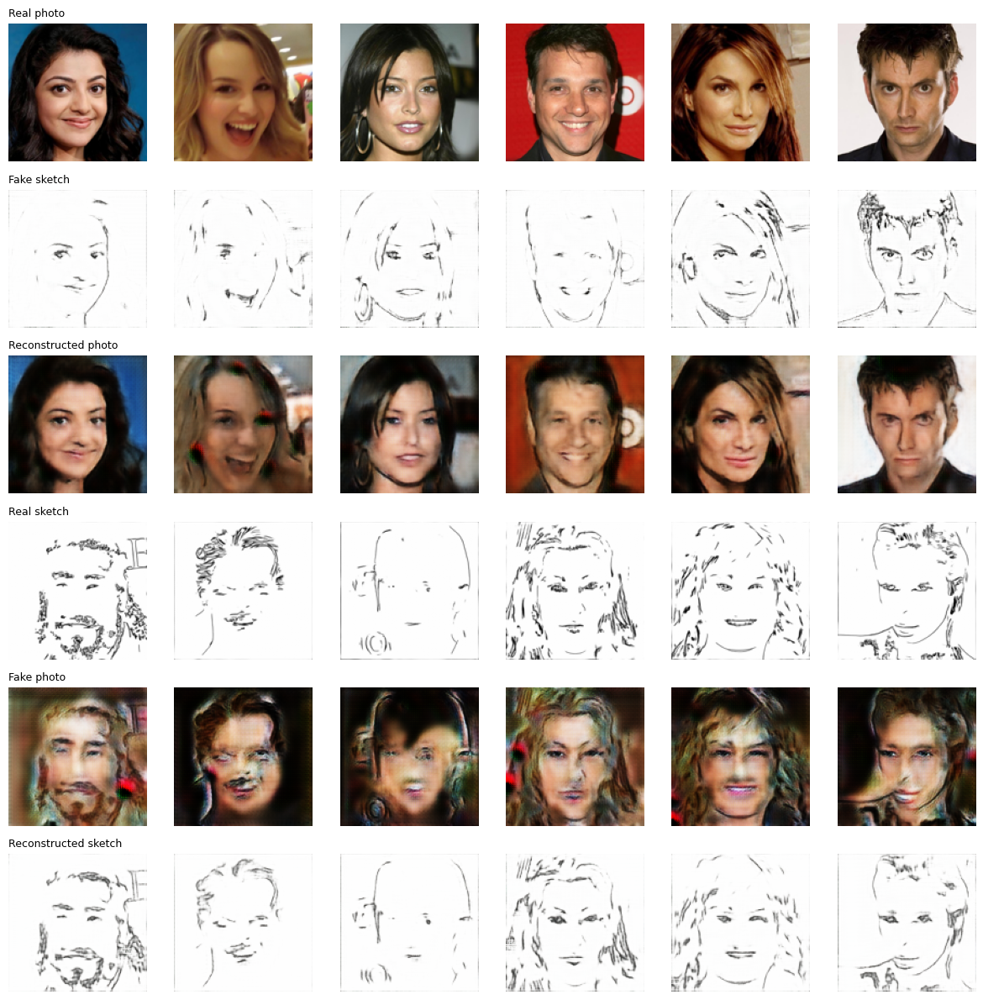

Epoch 20/30 | G_gan 1.062 D 0.242 cyc 1.598 idt 0.566 | lr 1.38e-04 | 230s
Epoch 21/30 | G_gan 0.990 D 0.250 cyc 1.564 idt 0.554 | lr 1.25e-04 | 228s
Epoch 22/30 | G_gan 1.000 D 0.254 cyc 1.530 idt 0.534 | lr 1.13e-04 | 228s
Epoch 23/30 | G_gan 1.056 D 0.229 cyc 1.521 idt 0.532 | lr 1.00e-04 | 229s
Epoch 24/30 | G_gan 1.036 D 0.237 cyc 1.493 idt 0.521 | lr 8.75e-05 | 229s


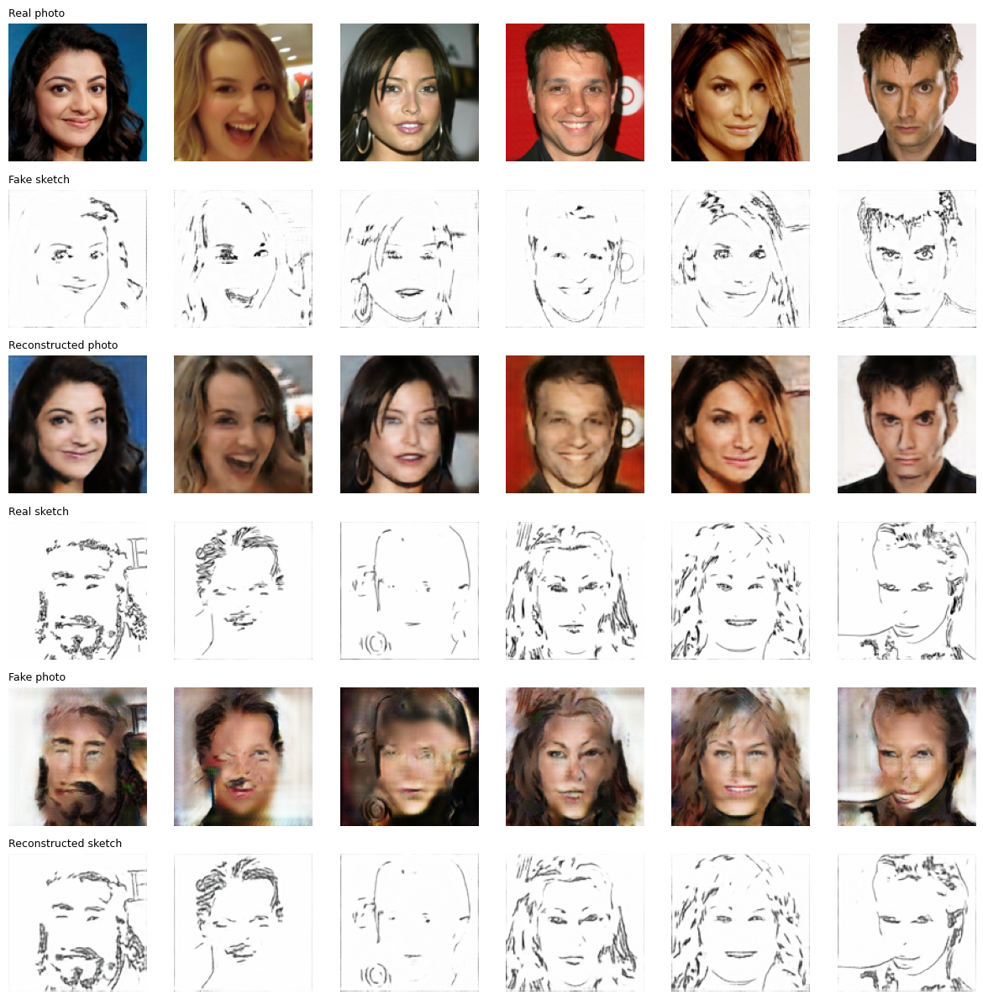

Epoch 25/30 | G_gan 0.988 D 0.237 cyc 1.457 idt 0.516 | lr 7.50e-05 | 229s
Epoch 26/30 | G_gan 1.041 D 0.228 cyc 1.435 idt 0.494 | lr 6.25e-05 | 228s
Epoch 27/30 | G_gan 1.035 D 0.229 cyc 1.411 idt 0.483 | lr 5.00e-05 | 229s
Epoch 28/30 | G_gan 1.123 D 0.205 cyc 1.395 idt 0.474 | lr 3.75e-05 | 229s
Epoch 29/30 | G_gan 1.127 D 0.204 cyc 1.374 idt 0.465 | lr 2.50e-05 | 228s


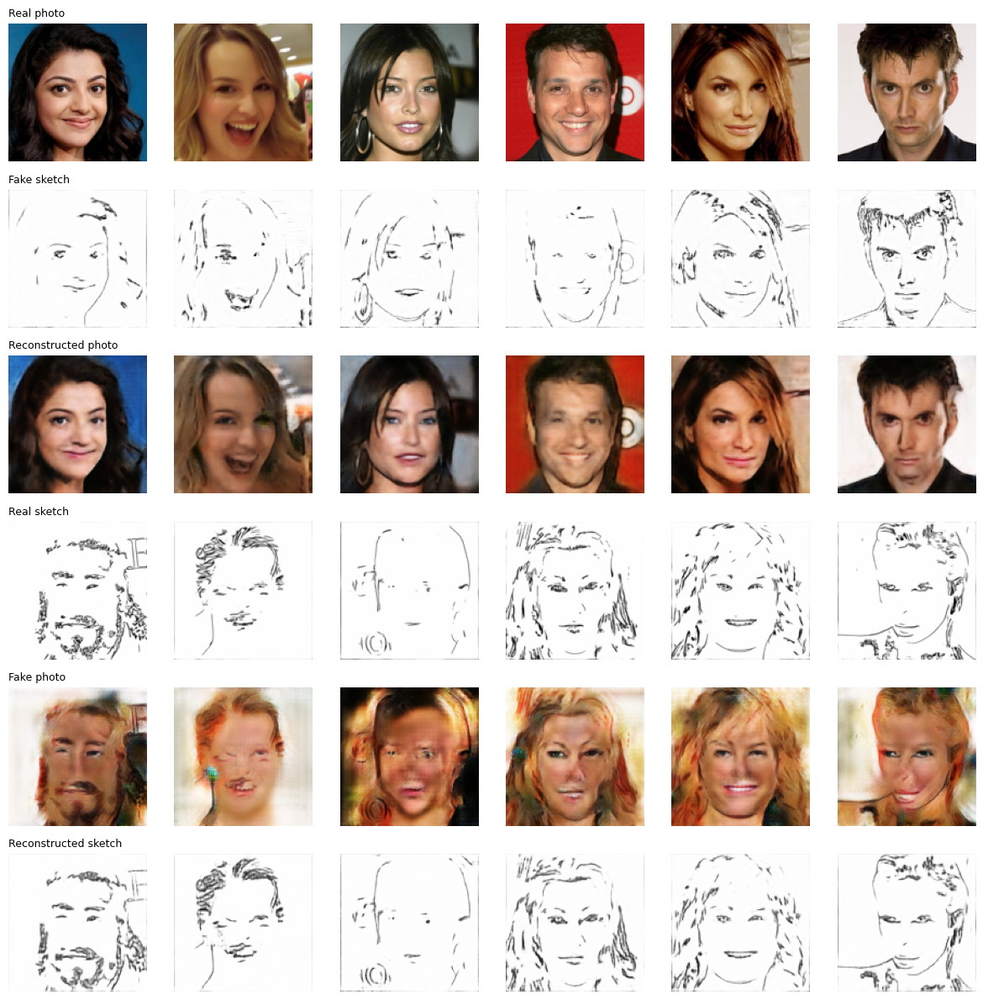

Epoch 30/30 | G_gan 1.112 D 0.200 cyc 1.355 idt 0.460 | lr 1.25e-05 | 229s


In [12]:
t_start = time.time()
G_AB.train(); G_BA.train(); D_A.train(); D_B.train()

for ep in range(start_epoch, EPOCHS):
    t0 = time.time(); s = {'G': 0, 'D': 0, 'cyc': 0, 'idt': 0}; n = 0
    for real_A, real_B in train_dl:
        real_A, real_B = real_A.to(device), real_B.to(device)

        # ---------- Generators ----------
        optG.zero_grad()
        loss_idt = (l1(G_AB(real_B), real_B) + l1(G_BA(real_A), real_A)) * LAMBDA_ID    # identity
        fake_B, fake_A = G_AB(real_A), G_BA(real_B)
        pB, pA = D_B(fake_B), D_A(fake_A)
        loss_gan = mse(pB, torch.ones_like(pB)) + mse(pA, torch.ones_like(pA))          # fool D
        loss_cyc = (l1(G_BA(fake_B), real_A) + l1(G_AB(fake_A), real_B)) * LAMBDA_CYC   # cycle
        loss_G = loss_gan + loss_cyc + loss_idt
        loss_G.backward(); optG.step()

        # ---------- Discriminators ----------
        optD.zero_grad()
        fa, fb = buf_A.push_pop(fake_A), buf_B.push_pop(fake_B)
        rA, rB, dfA, dfB = D_A(real_A), D_B(real_B), D_A(fa), D_B(fb)
        loss_D = 0.5 * (mse(rA, torch.ones_like(rA)) + mse(dfA, torch.zeros_like(dfA))) \
               + 0.5 * (mse(rB, torch.ones_like(rB)) + mse(dfB, torch.zeros_like(dfB)))
        loss_D.backward(); optD.step()

        b = real_A.size(0); n += b
        s['G'] += loss_gan.item() * b; s['D'] += loss_D.item() * b
        s['cyc'] += loss_cyc.item() * b; s['idt'] += loss_idt.item() * b

    schG.step(); schD.step()
    for k in s: history[k].append(s[k] / n)
    save_ckpt(ep + 1)                                                    # EVERY epoch
    make_grid(fixed_A, fixed_B, path=f'{OUT}/samples/ep{ep+1:03d}.png', show=((ep + 1) % 5 == 0 or ep == 0))
    print(f"Epoch {ep+1}/{EPOCHS} | G_gan {history['G'][-1]:.3f} D {history['D'][-1]:.3f} "
          f"cyc {history['cyc'][-1]:.3f} idt {history['idt'][-1]:.3f} "
          f"| lr {optG.param_groups[0]['lr']:.2e} | {time.time()-t0:.0f}s")

    if (time.time() - t_start) / 3600 > MAX_HOURS:
        print("Time budget reached. Checkpoint saved; re-run this cell (or a new session) to resume."); break

# Cell 11: Loss curves

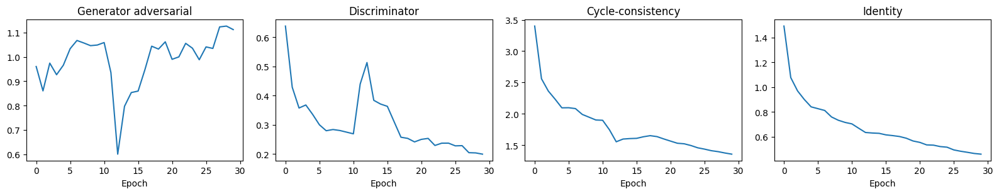

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for a, k, t in zip(ax, ['G', 'D', 'cyc', 'idt'],
                   ['Generator adversarial', 'Discriminator', 'Cycle-consistency', 'Identity']):
    a.plot(history[k]); a.set_title(t); a.set_xlabel('Epoch')
plt.tight_layout(); plt.savefig(f'{OUT}/loss_curves_cyclegan.png', dpi=150); plt.show()

# Cell 12: Test on held-out images (both directions)

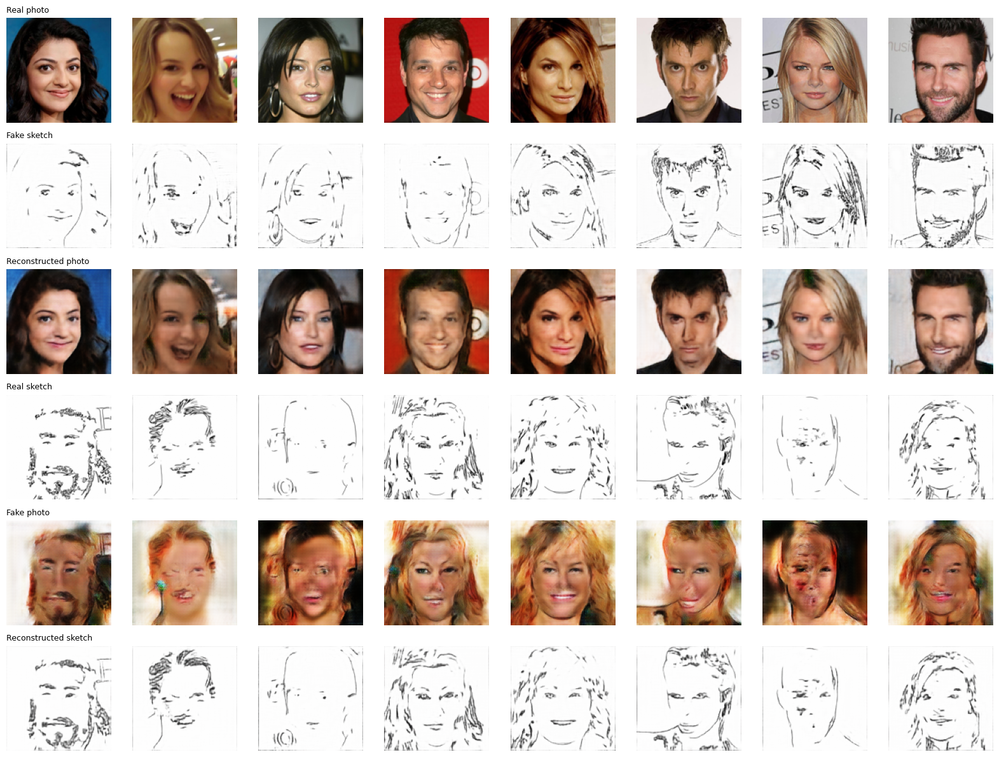

In [14]:
idx = list(range(min(8, len(testA), len(testB))))
tA = torch.stack([to_tensor(testA[i]) for i in idx]).to(device)
tB = torch.stack([to_tensor(testB[i]) for i in idx]).to(device)
make_grid(tA, tB, path=f'{OUT}/test_results.png', show=True)

# Cell 13: Export weights and calibrate the sketch detector

In [15]:
os.makedirs(f'{OUT}/flask_app/weights', exist_ok=True)
torch.save(G_AB.state_dict(), f'{OUT}/flask_app/weights/G_face2sketch.pth')
torch.save(G_BA.state_dict(), f'{OUT}/flask_app/weights/G_sketch2face.pth')

def saturation(a):   # how far the colour channels differ; sketches are near 0
    a = a.astype(float)
    return np.abs(a[..., 0] - a[..., 1]).mean() + np.abs(a[..., 1] - a[..., 2]).mean()

sa = [saturation(x) for x in arrA[:300]]; sb = [saturation(x) for x in arrB[:300]]
print(f"Photos : min {min(sa):.1f}  mean {np.mean(sa):.1f}")
print(f"Sketches: max {max(sb):.1f}  mean {np.mean(sb):.1f}")
print("Suggested threshold:", round((np.percentile(sa, 5) + np.percentile(sb, 95)) / 2, 1))

Photos : min 1.5  mean 45.1
Sketches: max 0.0  mean 0.0
Suggested threshold: 11.7


# Cell 14: Save outputs

In [16]:
for f in sorted(os.listdir(OUT)):
    if f.endswith(('.png', '.pth', '.csv')): print(f, f"{os.path.getsize(f'{OUT}/{f}')/1e6:.1f} MB")

gen_ep10.pth 62.7 MB
gen_ep20.pth 62.7 MB
gen_ep30.pth 62.7 MB
last.pth 254.6 MB
loss_curves_cyclegan.png 0.1 MB
test_results.png 1.2 MB


In [17]:
   import os
   os.remove('/kaggle/working/last.pth')